# 08 팀 모델 B 안정화 1: "명령 아님" 학습 데이터 늘리기

07의 E10(로그 멜 CNN)은 학습 손실은 꾸준히 내려갔지만 검증 결과가 에폭마다 크게 흔들렸습니다(정확도 0.33~0.89, 아는 단어 오작동 0.08~0.87). 07의 학습 묶음에서 "명령 아님" 단어는 20개 단어 × 153개 = 3,060개뿐이었고, 공식 학습 목록에는 이 단어들의 녹음이 47,623개 있습니다.

여기서는 **"명령 아님" 단어의 학습 녹음 수만** 바꾸고 나머지(CNN 구조, 20에폭, 학습률 1e-3, 배치 256, 명령어 30,769개, 잡음 구간 1,000개, 검증 묶음)는 E10과 같게 둡니다.

| 번호 | 단어마다 | "명령 아님" 단어 합계 | 학습 묶음 크기 |
|---|---|---|---|
| E10r | 153 (07과 같음, 다시 실행) | 3,060 | 34,829 |
| E11 | 600 | 12,000 | 43,769 |
| E12 | 1,400 (가장 적은 tree가 1,407개) | 28,000 | 59,769 |
| E13 | 전부 (단어마다 1,407~3,250개) | 47,623 | 79,392 |
| E14 | 전부 + 클래스 가중치 ("명령 아님"의 가중치 합을 E10r과 같게) | 47,623 | 79,392 |

E13은 녹음 종류(다양성)와 "명령 아님" 비율이 함께 늘어서, 결과가 바뀌어도 어느 쪽 때문인지 나눌 수 없습니다. E14는 녹음은 E13과 같이 전부 쓰되 손실에서 "명령 아님" 한 개의 가중치를 (E10r의 "명령 아님" 수) / (E13의 "명령 아님" 수)로 낮춰, 비율은 E10r과 같게 둡니다(`cross_entropy(weight=...)`). 그래서 E10r → E14는 다양성만, E14 → E13은 비율만 바뀐 비교입니다.

- 작은 단계는 큰 단계에 포함됩니다(07에서 쓴 153개를 먼저 넣고 나머지는 무작위 순서).
- 검증·시험 묶음은 바꾸지 않습니다. 화자 기준 공식 분할이라 학습에 넣는 녹음은 검증·시험 화자와 겹치지 않습니다.
- 흔들림은 숫자로 잽니다: 시드 2개로 반복하고, 최고 에폭 결과와 함께 **마지막 5에폭 검증 매크로 F1의 평균·표준편차**, 6에폭 이후 아는 단어 오작동률의 최소~최대를 적습니다.

Colab: 런타임 유형 T4 GPU → 모두 실행. `USE_DRIVE = True`면 07에서 저장한 검증 스펙트로그램을 다시 씁니다.

In [1]:
# 셀 1. 설정과 버전
import os, sys, time, random, copy, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio
import soundfile as sf
import matplotlib.pyplot as plt

SMOKE = False                  # True: 클래스마다 몇 개만, 1에폭 (결과 숫자는 쓰지 않음)
USE_DRIVE = False              # True: Colab에서 Google Drive를 연결해 스펙트로그램을 Drive에 저장
SEEDS = [0, 1]
LEVELS = {"E10r": (153, False), "E11": (600, False), "E12": (1400, False), "E13": (None, False), "E14": (None, True)}
# (번호: "명령 아님" 단어마다 학습 녹음 수 (None = 전부), 클래스 가중치로 비율을 E10r과 같게 할지)
DATA_ROOT = "data"
CSV = "splits_11class.csv"
CSV_URL = "https://raw.githubusercontent.com/yuchanghun/DL_26_02_Team2/main/splits_11class.csv"
CACHE_DIR = "cache"
SR = 16000
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
UNSEEN = ["backward", "follow", "forward", "learn", "visual"]
OTHER = "other"
LABELS = COMMANDS + [OTHER]
K = len(LABELS)
B_EPOCHS, B_LR, B_BATCH = 20, 1e-3, 256          # E10과 같음
B_CHANNELS = [16, 32, 64, 128]

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/DL_T02_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
if SMOKE:
    B_EPOCHS = 2
    LEVELS = {"E10r": (3, False), "E11": (6, False), "E12": (10, False), "E13": (None, False), "E14": (None, True)}
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__, "| pandas", pd.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if AMP else "GPU 없음 → CPU", "| SMOKE", SMOKE, "| 저장 위치", CACHE_DIR)

python 3.13.16 | torch 2.14.1+cu130 | torchaudio 2.11.0+cu130 | pandas 2.2.3
device: cuda | Tesla T4 | SMOKE False | 저장 위치 cache


In [2]:
# 셀 2. 데이터: 07의 목록 + 공식 학습 목록의 "명령 아님" 단어 전부
os.makedirs(DATA_ROOT, exist_ok=True)
sc = torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset="training")    # 공식 학습 목록 (검증·시험 목록 제외)
BASE_DIR = os.path.dirname(sc._path)
if not os.path.exists(CSV):
    urllib.request.urlretrieve(CSV_URL, CSV)
table = pd.read_csv(CSV)
table = table[table.split.isin(["train", "val"])].reset_index(drop=True)      # 시험 묶음은 쓰지 않음
base_train = table[table.split == "train"]

rows = []
for i in range(len(sc)):
    path, _, word, spk, _ = sc.get_metadata(i)
    if word in COMMANDS or word in UNSEEN:
        continue
    rows.append({"split": "train", "path": path.replace("\\", "/"), "word": word, "speaker": spk,
                 "label": OTHER, "group": "seen_other", "start": 0, "gain": 1.0})
pool = pd.DataFrame(rows)
assert pool.word.nunique() == 20
used = set(base_train[base_train.group == "seen_other"].path)
assert used <= set(pool.path), "07에서 쓴 녹음이 공식 학습 목록에 있어야 함"
rng = np.random.default_rng(0)
pool["first"] = ~pool.path.isin(used)                        # 07에서 쓴 153개가 먼저 오게
pool["rnd"] = rng.random(len(pool))
pool = pool.sort_values(["word", "first", "rnd"]).drop(columns=["first", "rnd"])
pool["rank"] = pool.groupby("word").cumcount()                # 단어 안에서 순서 → rank < n 이면 n개 사용

rest = base_train[base_train.group != "seen_other"].assign(rank=-1)
if SMOKE:
    rest = rest.groupby("label").head(10)
    pool = pool[pool["rank"] < 20]
train_all = pd.concat([rest, pool], ignore_index=True)
val = table[table.split == "val"].reset_index(drop=True)
if SMOKE:
    val = val.groupby(["label", "group"], group_keys=False).sample(frac=1.0, random_state=0)   # 07의 SMOKE와 같은 고르기
    val = val.groupby(["label", "group"]).head(10).reset_index(drop=True)
L2I = {l: i for i, l in enumerate(LABELS)}
Y_ALL = torch.tensor(train_all.label.map(L2I).values)
Y_VAL = torch.tensor(val.label.map(L2I).values)
GROUP_VAL = val.group.values

def subset(n):
    return ((train_all.group != "seen_other") | (n is None) | (train_all["rank"] < (n or 0))).to_numpy(copy=True)

print("공식 학습 목록의 '명령 아님' 단어 녹음:", len(pool), "| 단어마다 최소", pool.groupby("word").size().min(), "최대", pool.groupby("word").size().max())
def n_other(n):
    return int((Y_ALL[torch.from_numpy(subset(n))] == L2I[OTHER]).sum())
W_OTHER = n_other(LEVELS["E10r"][0]) / n_other(None)      # E14: "명령 아님" 한 개의 손실 가중치
def name(n, weighted):
    return ("전부" if n is None else str(n)) + (" + 가중치" if weighted else "")
for eid, (n, weighted) in LEVELS.items():
    m = subset(n)
    k = n_other(n)
    if weighted:
        eff = k * W_OTHER / (m.sum() - k + k * W_OTHER)
        print(f"  {eid}: 단어마다 {name(n, weighted)} → 학습 {m.sum():,}개, '명령 아님' 가중치 {W_OTHER:.4f} → 가중치 반영 비율 {eff:.1%}")
    else:
        print(f"  {eid}: 단어마다 {name(n, weighted)} → 학습 {m.sum():,}개, '명령 아님' 비율 {k / m.sum():.1%}")
print(f"  검증: {len(val):,}개, '명령 아님' 비율 {(Y_VAL == L2I[OTHER]).float().mean():.1%}")

100%|██████████| 2.26G/2.26G [00:18<00:00, 129MB/s]


공식 학습 목록의 '명령 아님' 단어 녹음: 47623 | 단어마다 최소 1407 최대 3250
  E10r: 단어마다 153 → 학습 34,829개, '명령 아님' 비율 11.7%
  E11: 단어마다 600 → 학습 43,769개, '명령 아님' 비율 29.7%
  E12: 단어마다 1400 → 학습 59,769개, '명령 아님' 비율 48.5%
  E13: 단어마다 전부 → 학습 79,392개, '명령 아님' 비율 61.2%
  E14: 단어마다 전부 + 가중치 → 학습 79,392개, '명령 아님' 가중치 0.0835 → 가중치 반영 비율 11.7%
  검증: 9,400개, '명령 아님' 비율 60.6%


In [3]:
# 셀 3. 소리 읽기 → 로그 멜 (07과 같은 설정, 저장해 두고 다시 씀)
def load_row(r):
    """06 노트북과 같은 규칙: 잡음은 start부터 1초를 잘라 gain을 곱함, 단어는 1초로 맞춤"""
    if r.group == "noise":
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32", start=int(r.start), frames=SR)
        x = x * float(r.gain)
    else:
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32")
    return np.pad(x, (0, max(0, SR - len(x))))[:SR]

class Rows(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        return load_row(self.df.iloc[i])

def cached(name, fn):
    path = os.path.join(CACHE_DIR, f"{name}{'_smoke' if SMOKE else ''}.pt")
    if os.path.exists(path):
        d = torch.load(path)
        print(f"  {name}: 저장된 것 사용 (처음 계산 {d['sec']:.0f}초)")
        return d
    d = fn()
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save(d, path)
    return d

mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=400, hop_length=160, n_mels=64).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)
mfcc = torchaudio.transforms.MFCC(sample_rate=SR, n_mfcc=40, melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 64}).to(device)

def spec(df, name, with_mfcc=False):
    def run():
        M, F, t0 = [], [], time.time()
        dl = torch.utils.data.DataLoader(Rows(df), batch_size=256, shuffle=False,
                                         num_workers=2 if os.name != "nt" else 0, collate_fn=lambda b: np.stack(b))
        with torch.no_grad():
            for x in dl:
                x = torch.from_numpy(x).to(device)
                M.append(to_db(mel(x)).half().cpu())
                if with_mfcc:
                    c = mfcc(x)
                    F.append(torch.cat([c.mean(-1), c.std(-1)], 1).cpu())
        d = {"mel": torch.cat(M).unsqueeze(1), "sec": time.time() - t0}
        if with_mfcc:
            d["mfcc"] = torch.cat(F)
        print(f"  {name}: 로그 멜 {tuple(d['mel'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run)

MEL_ALL = spec(train_all, "spec08_train_pool")["mel"]
MEL_VAL = spec(val, "spec11_val", with_mfcc=True)["mel"]          # 07과 같은 이름·내용 → Drive에 있으면 다시 씀
assert len(MEL_ALL) == len(train_all) and len(MEL_VAL) == len(val)

  spec08_train_pool: 로그 멜 (79392, 1, 64, 101) (39초)
  spec11_val: 로그 멜 (9400, 1, 64, 101) (8초)


In [4]:
# 셀 4. 평가 함수와 팀 모델 B (07의 E10과 같은 코드)
def evaluate(pred, y=None, groups=None):
    y = Y_VAL if y is None else y
    groups = GROUP_VAL if groups is None else groups
    pred, y = pred.cpu(), y.cpu()
    cm = torch.bincount(y * K + pred, minlength=K * K).reshape(K, K).float()
    tp = cm.diag()
    prec, rec = tp / cm.sum(0).clamp(min=1), tp / cm.sum(1).clamp(min=1)
    f1 = 2 * prec * rec / (prec + rec).clamp(min=1e-12)
    p, t = pred.numpy(), y.numpy()
    oth = L2I[OTHER]
    is_cmd = t != oth
    res = {"acc": (tp.sum() / cm.sum()).item(), "f1": f1.mean().item(), "cm": cm,
           "miss": float(np.mean(p[is_cmd] == oth)),
           "confuse": float(np.mean((p[is_cmd] != oth) & (p[is_cmd] != t[is_cmd])))}
    for g in ["seen_other", "noise"]:
        m = groups == g
        res[f"fa_{g}"] = float(np.mean(p[m] != oth)) if m.any() else float("nan")
    return res

class KWSCNN(nn.Module):
    def __init__(self, channels=B_CHANNELS, n_classes=K):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c_in, n_classes)
    def forward(self, x):
        return self.fc(self.pool(self.features(x)).flatten(1))

def train_cnn(mask, seed, w_other=1.0):
    """mask로 고른 학습 녹음으로 E10과 같은 방식으로 학습. 에폭마다 검증 지표를 남기고 매크로 F1 최고 에폭을 돌려줌"""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cw = torch.ones(K, device=device); cw[L2I[OTHER]] = w_other    # 클래스 가중치 (E14만 1이 아님)
    cnn = KWSCNN().to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    scaler = torch.amp.GradScaler(enabled=AMP)
    best, hist, t_start = None, [], time.time()
    for ep in range(B_EPOCHS):
        cnn.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx], weight=cw)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(idx)
        cnn.eval()
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            pred = torch.cat([cnn(Xva[i:i + 1024]).argmax(1) for i in range(0, len(Xva), 1024)])
        r = evaluate(pred)
        hist.append({"loss": tot / len(Xtr), "acc": r["acc"], "f1": r["f1"], "fa": r["fa_seen_other"], "miss": r["miss"], "sec": time.time() - t0})
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    best["sec"] = time.time() - t_start
    best["params"] = sum(p.numel() for p in cnn.parameters())
    return best, pd.DataFrame(hist)

In [5]:
# 셀 5. 학습: 실험 5개 × 시드 2개, 에폭마다 검증
RUNS = []
for eid, (n, weighted) in LEVELS.items():
    mask = subset(n)
    for seed in SEEDS:
        best, h = train_cnn(mask, seed, W_OTHER if weighted else 1.0)
        late = h.iloc[-5:]                     # 마지막 5에폭
        after = h.iloc[5:] if len(h) > 5 else h  # 6에폭 이후
        RUNS.append({"번호": eid, "단어마다": name(n, weighted), "학습 수": int(mask.sum()), "시드": seed,
                     "best": best, "hist": h,
                     "최고 F1": best["f1"], "최고 에폭": best["epoch"],
                     "마지막5 F1 평균": late.f1.mean(), "마지막5 F1 표준편차": late.f1.std(ddof=0),
                     "오작동 최소": after.fa.min(), "오작동 최대": after.fa.max(),
                     "에폭당 초": h.sec.mean(), "시간(초)": best["sec"]})
        print(f"{eid} (단어마다 {name(n, weighted)}, 학습 {mask.sum():,}개) 시드 {seed}: "
              f"최고 F1 {best['f1']:.4f} ({best['epoch']}에폭) | 마지막 5에폭 F1 {late.f1.mean():.4f} ± {late.f1.std(ddof=0):.4f} | "
              f"6에폭 이후 아는 단어 오작동 {after.fa.min():.3f}~{after.fa.max():.3f} | 에폭당 {h.sec.mean():.1f}초")
        print("   에폭별 검증 F1:", " ".join(f"{v:.2f}" for v in h.f1))

E10r (단어마다 153, 학습 34,829개) 시드 0: 최고 F1 0.8902 (15에폭) | 마지막 5에폭 F1 0.8231 ± 0.0252 | 6에폭 이후 아는 단어 오작동 0.046~0.536 | 에폭당 3.4초
   에폭별 검증 F1: 0.41 0.68 0.71 0.70 0.64 0.71 0.65 0.69 0.81 0.62 0.77 0.82 0.78 0.86 0.89 0.84 0.84 0.83 0.83 0.77
E10r (단어마다 153, 학습 34,829개) 시드 1: 최고 F1 0.8640 (16에폭) | 마지막 5에폭 F1 0.7738 ± 0.0852 | 6에폭 이후 아는 단어 오작동 0.106~0.760 | 에폭당 3.5초
   에폭별 검증 F1: 0.44 0.54 0.55 0.78 0.77 0.80 0.60 0.67 0.64 0.80 0.81 0.81 0.68 0.80 0.65 0.86 0.70 0.64 0.82 0.84
E11 (단어마다 600, 학습 43,769개) 시드 0: 최고 F1 0.9034 (20에폭) | 마지막 5에폭 F1 0.8690 ± 0.0186 | 6에폭 이후 아는 단어 오작동 0.027~0.526 | 에폭당 4.4초
   에폭별 검증 F1: 0.44 0.71 0.77 0.77 0.68 0.69 0.83 0.84 0.83 0.73 0.88 0.70 0.89 0.90 0.77 0.85 0.87 0.87 0.85 0.90
E11 (단어마다 600, 학습 43,769개) 시드 1: 최고 F1 0.9121 (20에폭) | 마지막 5에폭 F1 0.8854 ± 0.0266 | 6에폭 이후 아는 단어 오작동 0.035~0.462 | 에폭당 4.4초
   에폭별 검증 F1: 0.65 0.73 0.86 0.88 0.80 0.86 0.74 0.70 0.74 0.68 0.77 0.83 0.86 0.80 0.89 0.89 0.90 0.83 0.89 0.91
E12 (단어마다 1400, 학습 59,769개) 시드 0: 최고 F1 0.9290

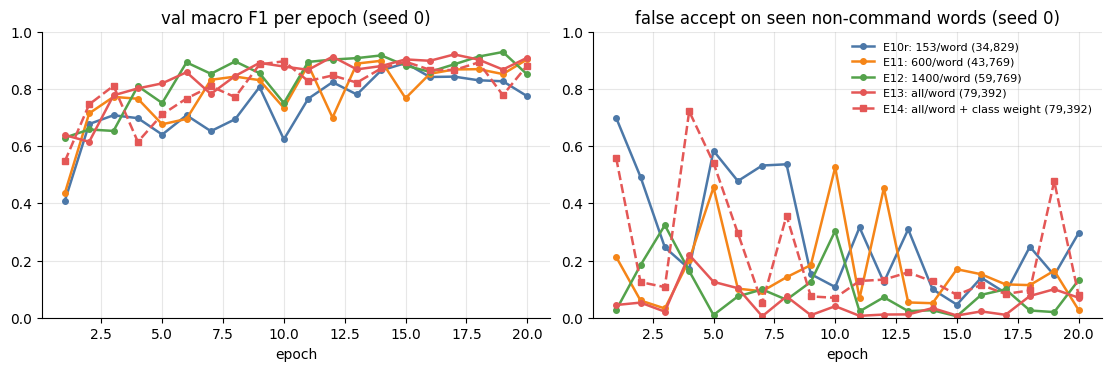

In [6]:
# 셀 6. 에폭별 곡선 (시드 0): 검증 매크로 F1과 아는 단어 오작동률
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#E45756"]   # 실험마다 고정 색, E14는 E13과 같은 색 점선
for c, (eid, (n, weighted)) in zip(colors, LEVELS.items()):
    run = next(r for r in RUNS if r["번호"] == eid and r["시드"] == SEEDS[0])
    h = run["hist"]; ep = np.arange(1, len(h) + 1)
    lab = f"{eid}: {n if n else 'all'}/word" + (" + class weight" if weighted else "") + f" ({run['학습 수']:,})"
    st = "s--" if weighted else "o-"
    ax[0].plot(ep, h.f1, st, color=c, ms=4, lw=1.8, label=lab)
    ax[1].plot(ep, h.fa, st, color=c, ms=4, lw=1.8, label=lab)
ax[0].set_title("val macro F1 per epoch (seed 0)"); ax[0].set_xlabel("epoch"); ax[0].set_ylim(0, 1)
ax[1].set_title("false accept on seen non-command words (seed 0)"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, 1)
for a in ax:
    a.grid(alpha=.3); a.spines[["top", "right"]].set_visible(False)
ax[1].legend(fontsize=8, frameon=False)
os.makedirs("figs", exist_ok=True)
fig.savefig("figs/08_epoch_curves.png", dpi=150)
plt.show()

In [7]:
# 셀 7. 결과 표 (검증 묶음). 위: 시드마다, 아래: 실험마다 시드 평균
pd.set_option("display.width", 220)
rows = []
for r in RUNS:
    b = r["best"]
    rows.append({"번호": r["번호"], "단어마다": r["단어마다"], "학습 수": f"{r['학습 수']:,}", "시드": r["시드"],
                 "정확도": b["acc"], "매크로 F1": b["f1"], "오작동(아는 단어)": b["fa_seen_other"], "오작동(잡음)": b["fa_noise"],
                 "놓침": b["miss"], "명령 혼동": b["confuse"], "최고 에폭": r["최고 에폭"],
                 "마지막5 F1": f"{r['마지막5 F1 평균']:.4f} ± {r['마지막5 F1 표준편차']:.4f}",
                 "오작동 범위(6에폭~)": f"{r['오작동 최소']:.3f}~{r['오작동 최대']:.3f}", "에폭당 초": f"{r['에폭당 초']:.1f}"})
per_seed = pd.DataFrame(rows)
show = per_seed.copy()
for c in ["정확도", "오작동(아는 단어)", "오작동(잡음)", "놓침", "명령 혼동"]:
    show[c] = show[c].map(lambda v: f"{v:.2%}")
show["매크로 F1"] = show["매크로 F1"].map(lambda v: f"{v:.4f}")
print(show.to_string(index=False))

print()
agg = pd.DataFrame([{"번호": r["번호"], "단어마다": r["단어마다"], "최고 F1": r["최고 F1"], "오작동": r["best"]["fa_seen_other"],
                     "놓침": r["best"]["miss"], "마지막5 평균": r["마지막5 F1 평균"], "마지막5 표준편차": r["마지막5 F1 표준편차"]} for r in RUNS])
agg = agg.groupby(["번호", "단어마다"], sort=False).mean().reset_index()
for c in ["최고 F1", "마지막5 평균", "마지막5 표준편차"]:
    agg[c] = agg[c].map(lambda v: f"{v:.4f}")
for c in ["오작동", "놓침"]:
    agg[c] = agg[c].map(lambda v: f"{v:.2%}")
print(f"시드 {len(SEEDS)}개 평균 (최고 에폭 기준 지표, 마지막 5에폭 F1)")
print(agg.to_string(index=False))
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"device {device} | 시드 {SEEDS} | 검증 {len(val):,}개 | 20에폭, lr {B_LR}, 배치 {B_BATCH}")

  번호     단어마다   학습 수  시드    정확도 매크로 F1 오작동(아는 단어) 오작동(잡음)    놓침 명령 혼동  최고 에폭         마지막5 F1 오작동 범위(6에폭~) 에폭당 초
E10r      153 34,829   0 92.46% 0.8902      4.57%  14.53% 7.62% 4.19%     15 0.8231 ± 0.0252  0.046~0.536   3.4
E10r      153 34,829   1 90.02% 0.8640     10.65%   0.85% 4.10% 5.16%     16 0.7738 ± 0.0852  0.106~0.760   3.5
 E11      600 43,769   0 93.89% 0.9034      2.74%   2.56% 6.67% 4.62%     20 0.8690 ± 0.0186  0.027~0.526   4.4
 E11      600 43,769   1 94.06% 0.9121      4.28%   0.00% 4.89% 3.73%     20 0.8854 ± 0.0266  0.035~0.462   4.4
 E12     1400 59,769   0 95.30% 0.9290      1.97%   0.85% 6.00% 2.94%     19 0.8875 ± 0.0301  0.005~0.304   5.9
 E12     1400 59,769   1 95.29% 0.9283      2.53%   0.00% 4.97% 3.19%     15 0.8909 ± 0.0138  0.014~0.386   5.9
 E13       전부 79,392   0 94.88% 0.9204      1.02%   0.00% 8.07% 3.38%     17 0.8995 ± 0.0176  0.005~0.103   7.7
 E13       전부 79,392   1 95.36% 0.9276      2.37%   0.00% 4.64% 3.56%     13 0.8975 ± 0.0282  0.001~0.22